Example 1: 48280.npy (forged)


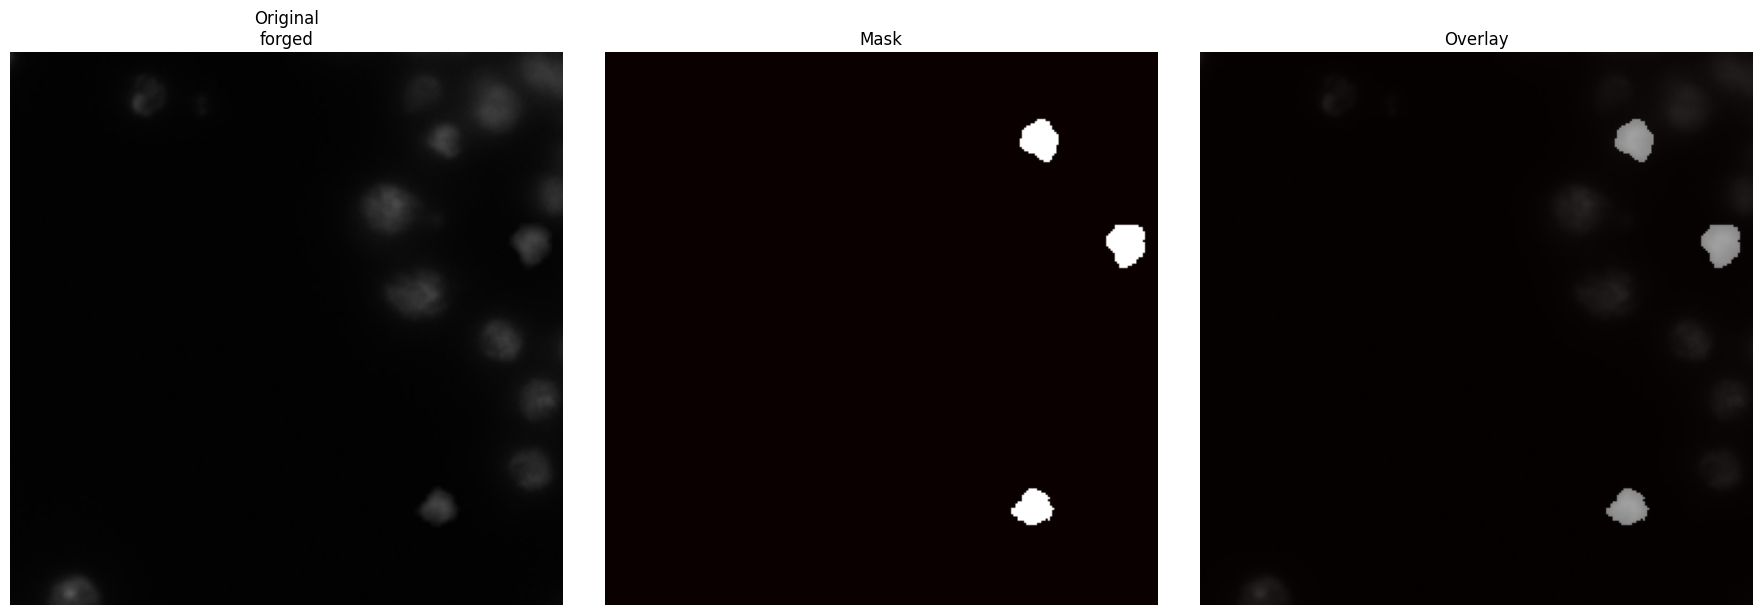

Example 2: 8081.npy (forged)


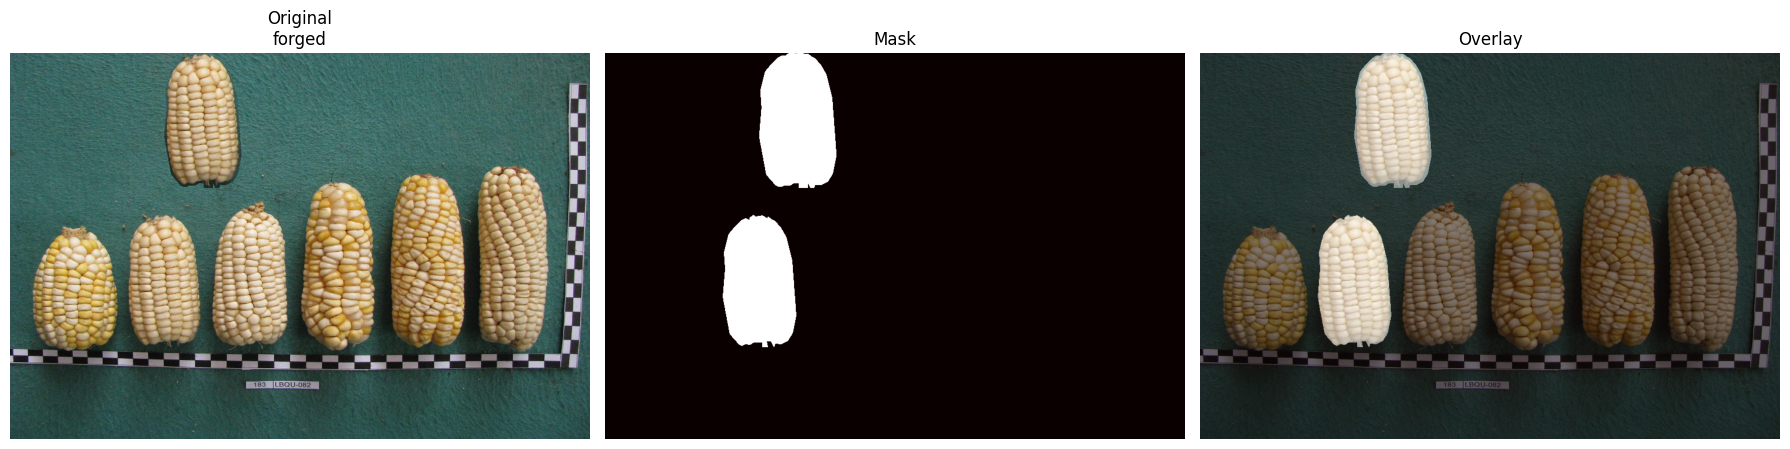

Example 3: 10799.npy (forged)


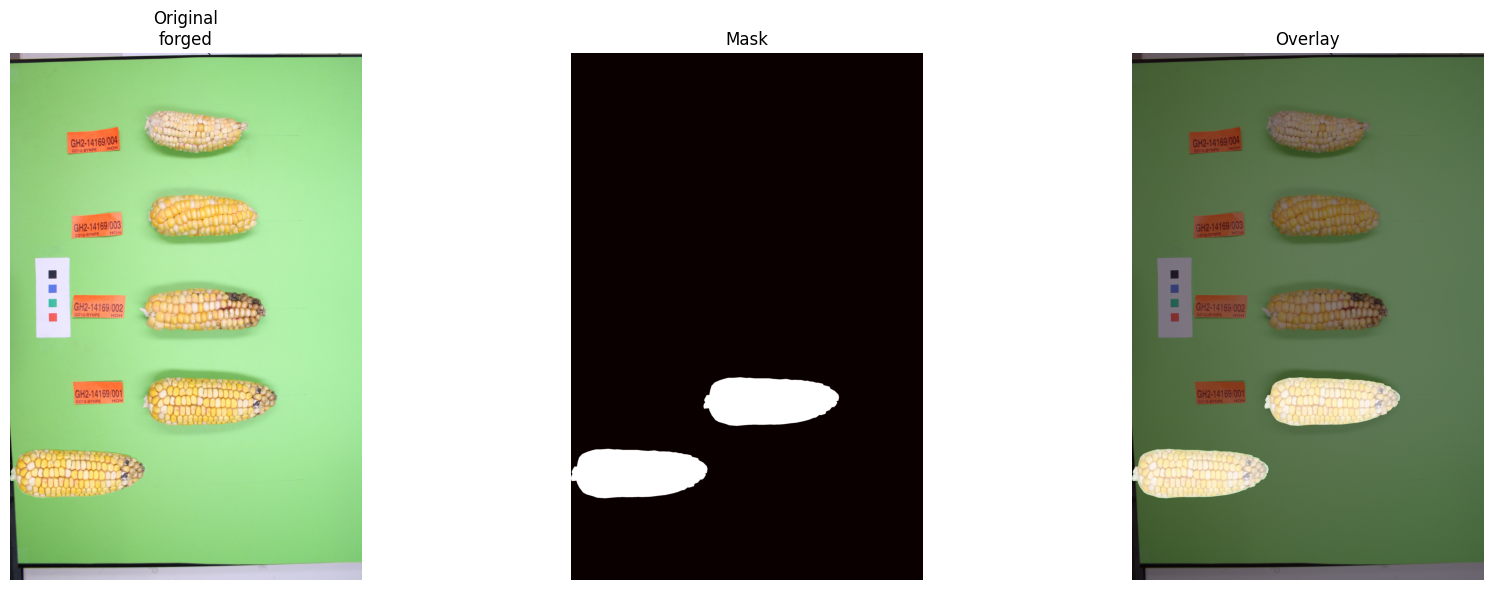

Example 4: 20882.npy (forged)


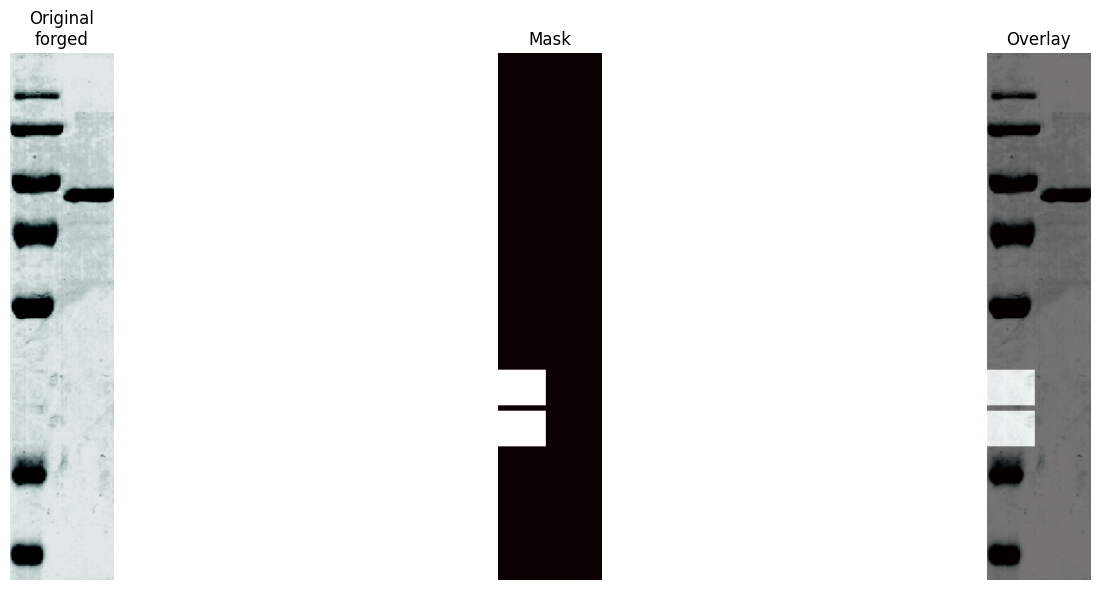

Example 5: 36986.npy (forged)


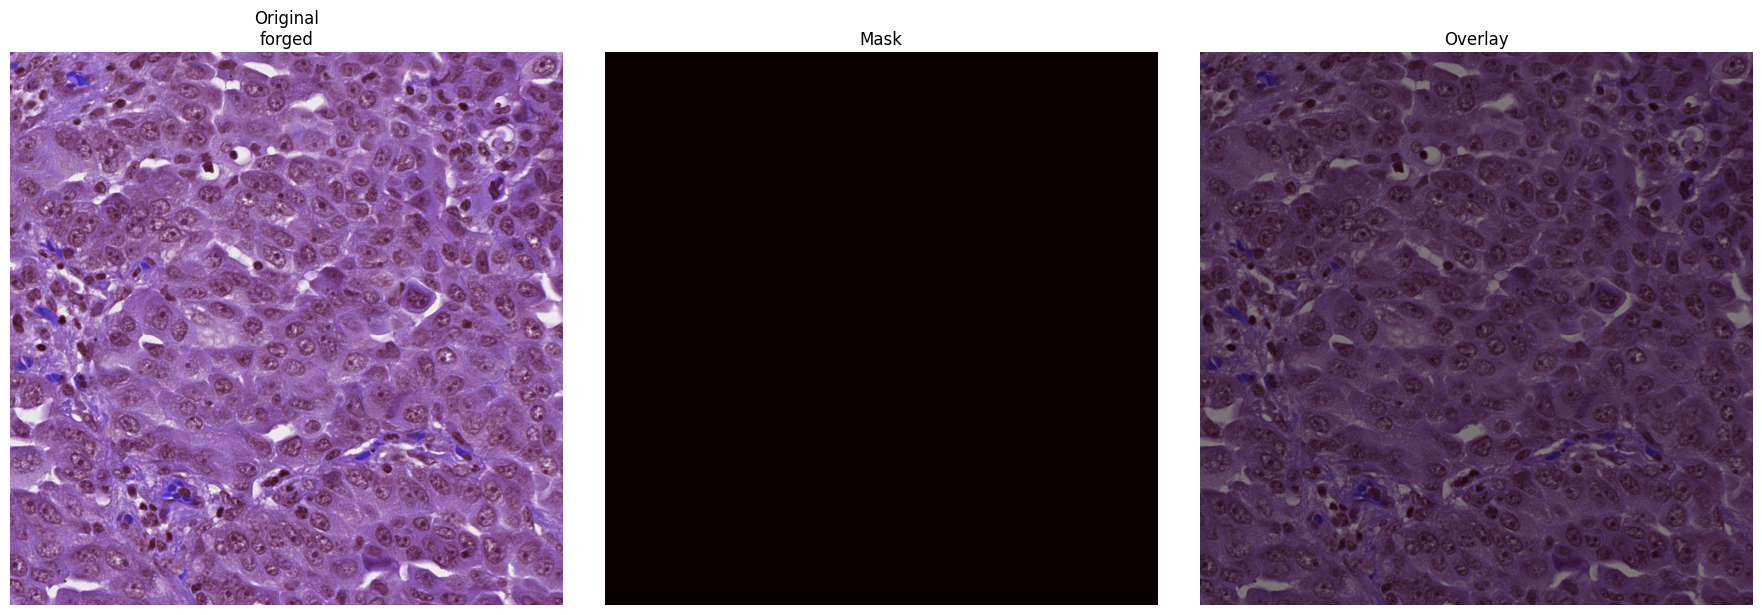

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

train_images_dir = Path('train_images')
train_masks_dir = Path('train_masks')
mask_files = list(train_masks_dir.glob('*.npy'))

def find_image(mask_name):
    name = mask_name.stem
    for folder in ['forged', 'authentic']:
        path = train_images_dir / folder / f'{name}.png'
        if path.exists():
            return path, folder
    return None, None

def getdata(index):
    mask_path = mask_files[index]
    image_path, label = find_image(mask_path)
    
    img = np.array(Image.open(image_path))
    if img.shape[2] == 4:
        img = img[:, :, :3]
    
    mask = np.load(mask_path).squeeze()
    if len(mask.shape) == 3:
        mask = mask[0] if mask.shape[0] == 1 else mask[:, :, 0]
    
    mask = mask.astype(np.float32)
    if mask.max() > 1:
        mask /= mask.max()
    
    if mask.shape != img.shape[:2]:
        mask = np.array(Image.fromarray((mask * 255).astype(np.uint8)).resize(img.shape[:2][::-1])) / 255.0
    
    return img, mask

def analyze_data():
    image_sizes = []
    mask_sizes = []
    labels = []
    
    for mask_file in mask_files:
        image_path, label = find_image(mask_file)
        if image_path:
            img = np.array(Image.open(image_path))
            mask = np.load(mask_file).squeeze()
            if len(mask.shape) == 3:
                mask = mask[0] if mask.shape[0] == 1 else mask[:, :, 0]
            
            image_sizes.append(img.shape[:2])
            mask_sizes.append(mask.shape[:2])
            labels.append(label)
    
    return {
        'image_sizes': np.array(image_sizes),
        'mask_sizes': np.array(mask_sizes),
        'labels': np.array(labels)
    }

def print_sizes(data, limit=20):
    print(f"{'Index':<8} {'Image Size':<15} {'Mask Size':<15} {'Match':<8}")
    print("-" * 50)
    for i in range(min(limit, len(data['image_sizes']))):
        img_size = f"{data['image_sizes'][i][0]}x{data['image_sizes'][i][1]}"
        mask_size = f"{data['mask_sizes'][i][0]}x{data['mask_sizes'][i][1]}"
        match = "✓" if np.array_equal(data['image_sizes'][i], data['mask_sizes'][i]) else "✗"
        print(f"{i:<8} {img_size:<15} {mask_size:<15} {match:<8}")
    if len(data['image_sizes']) > limit:
        print(f"\n... and {len(data['image_sizes']) - limit} more")

def visualize_with_mask(image_path, mask_path, label=None, alpha=0.5):
    img = np.array(Image.open(image_path))
    if img.shape[2] == 4:
        img = img[:, :, :3]
    
    mask = np.load(mask_path).squeeze()
    if len(mask.shape) == 3:
        mask = mask[0] if mask.shape[0] == 1 else mask[:, :, 0]
    
    mask = mask.astype(np.float32)
    if mask.max() > 1:
        mask /= mask.max()
    
        mask = np.array(Image.fromarray((mask * 255).astype(np.uint8)).resize(img.shape[:2][::-1])) / 255.0
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(img)
    axes[0].set_title(f'Original\n{label or ""}')
    axes[0].axis('off')
    axes[1].imshow(mask, cmap='hot')
    axes[1].set_title('Mask')
    axes[1].axis('off')
    axes[2].imshow(img)
    axes[2].imshow(mask, cmap='hot', alpha=alpha)
    axes[2].set_title('Overlay')
    axes[2].axis('off')
    plt.tight_layout()
    plt.show()

for i, mask_file in enumerate(mask_files[:5]):
    image_path, label = find_image(mask_file)
    if image_path:
        print(f"Example {i+1}: {mask_file.name} ({label})")
        visualize_with_mask(image_path, mask_file, label=label)


In [4]:
# Visualize specific image: visualize_with_mask(find_image(Path('train_masks/9042.npy'))[0], Path('train_masks/9042.npy'))


In [5]:
#data = analyze_data()


In [6]:
# Check authentic images
authentic_images = list((train_images_dir / 'authentic').glob('*.png'))
forged_images = list((train_images_dir / 'forged').glob('*.png'))

print(f"Authentic images: {len(authentic_images)}")
print(f"Forged images: {len(forged_images)}")
print(f"Total masks: {len(mask_files)}")

# Check how many authentic images have corresponding masks
authentic_with_masks = sum(1 for img in authentic_images if (train_masks_dir / f'{img.stem}.npy').exists())
forged_with_masks = sum(1 for img in forged_images if (train_masks_dir / f'{img.stem}.npy').exists())

print(f"\nAuthentic images with masks: {authentic_with_masks}/{len(authentic_images)}")
print(f"Forged images with masks: {forged_with_masks}/{len(forged_images)}")

# Check a few authentic image names vs mask names
print("\nSample authentic images:")
for img in authentic_images[:5]:
    mask_exists = (train_masks_dir / f'{img.stem}.npy').exists()
    print(f"  {img.name} -> mask exists: {mask_exists}")


Authentic images: 2377
Forged images: 2751
Total masks: 2751

Authentic images with masks: 2377/2377
Forged images with masks: 2751/2751

Sample authentic images:
  1804.png -> mask exists: True
  20751.png -> mask exists: True
  64649.png -> mask exists: True
  55494.png -> mask exists: True
  23502.png -> mask exists: True


In [7]:
print_sizes(data, limit=len(data['image_sizes'])) 

Index    Image Size      Mask Size       Match   
--------------------------------------------------
0        256x256         256x256         ✓       
1        666x1000        666x1000        ✓       
2        3888x2592       3888x2592       ✓       
3        501x98          501x98          ✓       
4        1105x1105       3x1105          ✗       
5        520x696         520x696         ✓       
6        159x1306        159x1306        ✓       
7        1200x1600       2x1200          ✗       
8        512x554         512x554         ✓       
9        256x320         256x320         ✓       
10       512x640         3x512           ✗       
11       666x1000        666x1000        ✓       
12       666x1000        666x1000        ✓       
13       204x858         204x858         ✓       
14       1200x1600       2x1200          ✗       
15       512x512         512x512         ✓       
16       666x1000        666x1000        ✓       
17       324x1878        324x1878        ✓       

In [8]:
# Classify images using the TensorFlow ResNet model
import tensorflow as tf
import numpy as np
from PIL import Image

# Load the model
tf_model = tf.saved_model.load('models/')
infer_fn = tf_model.signatures['serving_default']

def classify_image(image_path, model=infer_fn, top_k=5):
    """Classify an image and return top predictions"""
    # Load and preprocess image
    img = Image.open(image_path)
    if img.mode != 'RGB':
        img = img.convert('RGB')
    
    # Resize to reasonable size (model accepts variable size, but let's use standard)
    img = img.resize((224, 224))
    img_array = np.array(img).astype(np.float32) / 255.0
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    
    # Run inference
    predictions = model(inputs=tf.constant(img_array))
    logits = predictions['logits'].numpy()[0]
    
    # Get top-k predictions
    top_indices = np.argsort(logits)[-top_k:][::-1]
    top_probs = logits[top_indices]
    
    # Apply softmax to get probabilities
    exp_logits = np.exp(logits - np.max(logits))
    probs = exp_logits / np.sum(exp_logits)
    top_probs = probs[top_indices]
    
    return top_indices, top_probs

# Test with one of your images
test_image_path = train_images_dir / 'forged' / '48280.png'
if test_image_path.exists():
    indices, probs = classify_image(test_image_path)
    print(f"Top 5 predictions for {test_image_path.name}:")
    for i, (idx, prob) in enumerate(zip(indices, probs)):
        print(f"  {i+1}. Class {idx}: {prob*100:.2f}%")
else:
    print("Test image not found")

# Note: Class indices 0-999 correspond to ImageNet classes
# You can download ImageNet class names to see what each class represents


/Users/computer/dev/ai/pytorch/.venv_tf311/lib/python3.11/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):
2026-01-06 18:49:19.028195: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Max
2026-01-06 18:49:19.028225: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 64.00 GB
2026-01-06 18:49:19.028231: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 25.92 GB
2026-01-06 18:49:19.028249: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-01-06 18:49:19.028263: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice 

Top 5 predictions for 48280.png:
  1. Class 829: 11.40%
  2. Class 972: 8.04%
  3. Class 819: 3.58%
  4. Class 921: 2.19%
  5. Class 6: 1.57%


In [9]:
# Get ImageNet class names for better interpretation
import urllib.request
import json

# Download ImageNet class names
try:
    url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
    urllib.request.urlretrieve(url, "imagenet_classes.txt")
    
    with open("imagenet_classes.txt", "r") as f:
        imagenet_classes = [line.strip() for line in f.readlines()]
    
    print(f"Loaded {len(imagenet_classes)} ImageNet classes")
    
    # Now classify with class names
    test_image_path = train_images_dir / 'forged' / '48280.png'
    if test_image_path.exists():
        indices, probs = classify_image(test_image_path)
        print(f"\nTop 5 predictions for {test_image_path.name}:")
        for i, (idx, prob) in enumerate(zip(indices, probs)):
            class_name = imagenet_classes[idx] if idx < len(imagenet_classes) else f"Class {idx}"
            print(f"  {i+1}. {class_name}: {prob*100:.2f}%")
except Exception as e:
    print(f"Could not download class names: {e}")
    print("You can still use class indices (0-999)")

# Function to classify any image with names
def classify_with_names(image_path, top_k=5):
    """Classify image and return predictions with class names"""
    try:
        indices, probs = classify_image(image_path, top_k=top_k)
        results = []
        for idx, prob in zip(indices, probs):
            class_name = imagenet_classes[idx] if idx < len(imagenet_classes) else f"Class {idx}"
            results.append((class_name, prob))
        return results
    except:
        indices, probs = classify_image(image_path, top_k=top_k)
        return [(f"Class {idx}", prob) for idx, prob in zip(indices, probs)]


Loaded 1000 ImageNet classes

Top 5 predictions for 48280.png:
  1. streetcar: 11.40%
  2. cliff: 8.04%
  3. stage: 3.58%
  4. book jacket: 2.19%
  5. stingray: 1.57%


In [10]:
# Access all image sizes
print("All image sizes:", data['image_sizes'])

# Get unique sizes
print("\nUnique image sizes:", np.unique(data['image_sizes'], axis=0))

# Count by size
unique_sizes, counts = np.unique(data['image_sizes'], axis=0, return_counts=True)
for size, count in zip(unique_sizes, counts):
    print(f"Size {size}: {count} images")

# Filter by label
forged_indices = data['labels'] == 'forged'
authentic_indices = data['labels'] == 'authentic'
print(f"\nForged: {forged_indices.sum()}, Authentic: {authentic_indices.sum()}")


All image sizes: [[ 256  256]
 [ 666 1000]
 [3888 2592]
 ...
 [ 256  256]
 [1200 1600]
 [ 404  447]]

Unique image sizes: [[  64  434]
 [  64  814]
 [  64 1192]
 ...
 [2078  633]
 [2592 3888]
 [3888 2592]]
Size [ 64 434]: 2 images
Size [ 64 814]: 1 images
Size [  64 1192]: 1 images
Size [ 65 391]: 1 images
Size [ 65 440]: 1 images
Size [  65 1181]: 1 images
Size [ 66 319]: 2 images
Size [ 67 396]: 2 images
Size [ 67 398]: 2 images
Size [ 67 449]: 1 images
Size [ 68 391]: 1 images
Size [ 68 657]: 1 images
Size [ 68 697]: 2 images
Size [ 68 753]: 1 images
Size [ 68 875]: 1 images
Size [ 69 517]: 2 images
Size [ 69 807]: 1 images
Size [ 70 371]: 1 images
Size [ 70 448]: 1 images
Size [ 70 510]: 1 images
Size [ 70 625]: 1 images
Size [ 70 632]: 1 images
Size [ 72 589]: 1 images
Size [ 72 641]: 1 images
Size [ 73 464]: 1 images
Size [ 73 522]: 1 images
Size [ 73 565]: 1 images
Size [ 74 426]: 1 images
Size [ 74 505]: 1 images
Size [ 74 533]: 1 images
Size [ 74 534]: 1 images
Size [  75 1067

In [11]:
img, mask = getdata(0)  # Get first image and mask

In [12]:
mask[182]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [13]:
import tensorflow as tf
import tensorflow.keras as keras

# Load the SavedModel
model = tf.saved_model.load('models/')


In [14]:
print("Model signatures:", list(model.signatures.keys()))

# Get input/output info
infer = model.signatures['serving_default']
print("\nInput signature:", infer.structured_input_signature)
print("Output signature:", infer.structured_outputs)

# Get input shape
for input_name, input_spec in infer.structured_input_signature[1].items():
    print(f"\nInput '{input_name}':")
    print(f"  Shape: {input_spec.shape}")
    print(f"  Dtype: {input_spec.dtype}")

# Get output shape
for output_name, output_tensor in infer.structured_outputs.items():
    print(f"\nOutput '{output_name}':")
    print(f"  Shape: {output_tensor.shape}")
    print(f"  Dtype: {output_tensor.dtype}")

# List all available methods/attributes
print("\nAvailable attributes:", dir(model))

Model signatures: ['serving_default']

Input signature: ((), {'inputs': TensorSpec(shape=(None, None, None, 3), dtype=tf.float32, name='inputs')})
Output signature: {'logits': TensorSpec(shape=(None, 1001), dtype=tf.float32, name='logits')}

Input 'inputs':
  Shape: (None, None, None, 3)
  Dtype: <dtype: 'float32'>

Output 'logits':
  Shape: (None, 1001)
  Dtype: <dtype: 'float32'>

Available attributes: ['__call__', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_add_trackable_child', '_add_variable_with_custom_getter', '_checkpoint_dependencies', '_copy_trackable_to_cpu', '_deferred_dependencies', '_delete_tracking', '_deserialization_dependencies', '_deserialize_from_proto',

In [15]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow.keras.applications as applications
import numpy as np
from PIL import Image
import pandas as pd
from pathlib import Path


def build_unet(input_shape=(256, 256, 3), num_classes=1):
    inputs = keras.Input(shape=input_shape)

    base_model = applications.ResNet101(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    # skips: 1/2, 1/4, 1/8, 1/16, bottleneck 1/32
    s1 = base_model.get_layer("conv1_relu").output
    s2 = base_model.get_layer("conv2_block3_out").output
    s3 = base_model.get_layer("conv3_block4_out").output
    s4 = base_model.get_layer("conv4_block23_out").output
    b  = base_model.get_layer("conv5_block3_out").output

    def up_block(x, skip, filters):
        x = layers.Conv2DTranspose(filters, 3, strides=2, padding="same")(x)
        x = layers.Concatenate()([x, skip])
        x = layers.Conv2D(filters, 3, padding="same")(x)
        x = layers.ReLU()(x)
        x = layers.Conv2D(filters, 3, padding="same")(x)
        x = layers.ReLU()(x)
        return x

    x = up_block(b,  s4, 512)  # 1/16
    x = up_block(x,  s3, 256)  # 1/8
    x = up_block(x,  s2, 128)  # 1/4
    x = up_block(x,  s1,  64)  # 1/2

    # MISSING STEP BEFORE: go from 1/2 -> 1/1 (128->256)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)

    outputs = layers.Conv2D(num_classes, 1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs)
# Create model
print("Building model...")
model = build_unet(input_shape=(256, 256, 3), num_classes=1)
# model.summary()

import tensorflow as tf
import numpy as np
from PIL import Image

# Fix getdata crash: always RGB
def getdata(index):
    mask_path = mask_files[index]
    image_path, label = find_image(mask_path)

    img = np.array(Image.open(image_path).convert("RGB"), dtype=np.uint8)  # (H,W,3)

    mask = np.load(mask_path).squeeze()
    if mask.ndim == 3:
        if mask.shape[0] == 1:
            mask = mask[0]
        elif mask.shape[-1] == 1:
            mask = mask[..., 0]
        else:
            mask = mask[..., 0]
    mask = mask.astype(np.float32)
    if mask.max() > 1:
        mask /= mask.max()

    return img, mask

def create_dataset(indices, batch_size=4, img_size=(256, 256), training=False, cache=True, repeat=True):
    idxs = tf.constant(indices, dtype=tf.int32)
    ds = tf.data.Dataset.from_tensor_slices(idxs)

    if training:
        ds = ds.shuffle(len(indices), reshuffle_each_iteration=True)

    def _py_load(i):
        i = int(i)
        img, mask = getdata(i)
        return img, mask

    def _map(i):
        img, mask = tf.py_function(_py_load, [i], [tf.uint8, tf.float32])
        img.set_shape([None, None, 3])
        mask.set_shape([None, None])

        img = tf.image.resize(tf.cast(img, tf.float32), img_size) / 255.0
        mask = tf.image.resize(mask[..., None], img_size, method="nearest")
        mask = tf.clip_by_value(mask, 0.0, 1.0)
        return img, mask

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.apply(tf.data.experimental.ignore_errors())

    if cache:
        ds = ds.cache()
    if repeat:
        ds = ds.repeat()

    return ds.batch(batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)

# Data loading function
def create_dataset(indices, batch_size=4, img_size=(256, 256)):
    """Create TensorFlow dataset from indices"""
    
    def generator():
        for idx in indices:
            try:
                img, mask = getdata(idx)
                
                # Resize to fixed size
                img_resized = tf.image.resize(img, img_size)
                mask_resized = tf.image.resize(mask[..., None], img_size)
                
                # Normalize
                img_normalized = img_resized / 255.0
                mask_normalized = mask_resized / 255.0
                
                yield img_normalized, mask_normalized
            except Exception as e:
                print(f"Error loading index {idx}: {e}")
                continue
    
    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(*img_size, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(*img_size, 1), dtype=tf.float32)
        )
    )
    
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

test_size = 100
train_size = int(test_size * 0.8)


train_indices = list(range(0, train_size))
val_indices = list(range(train_size, test_size))

print(f"\nUsing {test_size} images total:")
print(f"  Training: {len(train_indices)}")
print(f"  Validation: {len(val_indices)}")

BATCH = 4
train_ds = create_dataset(train_indices, batch_size=BATCH, training=True, cache=True, repeat=True)
val_ds   = create_dataset(val_indices,   batch_size=BATCH, training=False, cache=True, repeat=True)


train_ds = train_ds.cache().repeat().prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.cache().repeat().prefetch(tf.data.AUTOTUNE)


# Use only 100 images for testing
# Split indices
exit

# Create datasets
print("\nCreating datasets...")
train_ds = create_dataset(train_indices, batch_size=4)
val_ds = create_dataset(val_indices, batch_size=4)

# Compile model
print("\nCompiling model...")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.IoU(num_classes=2, target_class_ids=[1], name='iou')]
)

# Callbacks
callbacks = [
    keras.callbacks.ModelCheckpoint(
        'best_model.h5', 
        save_best_only=True,
        monitor='val_loss',
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

# Train model
print("\nStarting training...")
print("=" * 50)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,  # Reduced for testing
    callbacks=callbacks,
    verbose=1
)

print("\nTraining completed!")

# Visualize training history
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Model Loss')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Model Accuracy')

plt.tight_layout()
plt.show()

# Test prediction on a few samples
print("\nTesting predictions on validation samples...")

def visualize_predictions(model, indices, num_samples=3):
    """Visualize model predictions"""
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5*num_samples))
    
    for i, idx in enumerate(indices[:num_samples]):
        img, true_mask = getdata(idx)
        original_shape = img.shape[:2]
        
        # Preprocess
        img_resized = tf.image.resize(img, (256, 256))
        img_tensor = tf.expand_dims(img_resized / 255.0, 0)
        
        # Predict
        pred = model.predict(img_tensor, verbose=0)
        pred_mask = pred[0, :, :, 0]
        
        # Resize back
        pred_mask_resized = tf.image.resize(
            pred_mask[..., None], 
            original_shape, 
            method='nearest'
        ).numpy()[:, :, 0]
        
        # Plot
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f'Original Image (idx {idx})')
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(true_mask, cmap='hot')
        axes[i, 1].set_title('True Mask')
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(pred_mask_resized, cmap='hot')
        axes[i, 2].set_title('Predicted Mask')
        axes[i, 2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Visualize some predictions
visualize_predictions(model, val_indices, num_samples=3)

# RLE encoding function for submission
def rle_encode(mask):
    """Run Length Encoding for submission"""
    pixels = mask.flatten()
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return ' '.join(str(x) for x in runs)

# Prediction function for submission format
def predict_and_submit(model, test_indices, img_size=(256, 256)):
    """Generate predictions in submission format"""
    submissions = []
    
    print(f"\nGenerating predictions for {len(test_indices)} images...")
    
    for i, idx in enumerate(test_indices):
        if i % 10 == 0:
            print(f"  Processing {i+1}/{len(test_indices)}...")
        
        try:
            img, _ = getdata(idx)
            original_shape = img.shape[:2]
            
            # Preprocess
            img_resized = tf.image.resize(img, img_size)
            img_tensor = tf.expand_dims(img_resized / 255.0, 0)
            
            # Predict
            pred = model.predict(img_tensor, verbose=0)
            pred_mask = (pred[0, :, :, 0] > 0.5).astype(np.uint8)
            
            # Resize back to original
            pred_mask_resized = tf.image.resize(
                pred_mask[..., None], 
                original_shape, 
                method='nearest'
            ).numpy()[:, :, 0]
            
            # Create submission entry
            if pred_mask_resized.sum() == 0:
                submissions.append({"case_id": idx, "annotation": "authentic"})
            else:
                rle = rle_encode(pred_mask_resized)
                submissions.append({"case_id": idx, "annotation": rle})
        except Exception as e:
            print(f"Error processing index {idx}: {e}")
            submissions.append({"case_id": idx, "annotation": "authentic"})
    
    return submissions

# Generate predictions (using validation set as test)
print("\nGenerating submission format predictions...")
# submissions = predict_and_submit(model, val_indices)

# Create submission file
# df = pd.DataFrame(submissions)
# df.to_csv('submission_test.csv', index=False)
# print(f"\nSubmission file saved: submission_test.csv")
# print(f"Total predictions: {len(submissions)}")
# print(f"Authentic predictions: {sum(1 for s in submissions if s['annotation'] == 'authentic')}")
# print(f"Forgery predictions: {sum(1 for s in submissions if s['annotation'] != 'authentic')}")

# print("\n" + "=" * 50)
# print("Complete! Model trained and tested on 100 images.")
# print("=" * 50)

Building model...

Using 100 images total:
  Training: 80
  Validation: 20


TypeError: create_dataset() got an unexpected keyword argument 'training'